In [1]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

df_klasifikasi = None
df_qa = None

for nama_file, isi_file in uploaded.items():
    data = pd.read_csv(io.BytesIO(isi_file))

    if "teks_laporan" in data.columns and "kategori" in data.columns:
        df_klasifikasi = data

    elif all(kolom in data.columns for kolom in [
        "Title", "Link", "Question", "Answer", "kategori"
    ]):
        df_qa = data

if df_klasifikasi is None or df_qa is None:
    raise ValueError(
        "Pastikan kedua dataset sudah di-upload "
        "dan nama kolomnya sesuai."
    )

print("Dataset klasifikasi:", df_klasifikasi.shape)
print("Dataset Legal QA:", df_qa.shape)

Saving dataset_klasifikasi_kasus_hukum_500 (3).csv to dataset_klasifikasi_kasus_hukum_500 (3).csv
Saving Indonesian_Legal_QA_543_Baris.csv to Indonesian_Legal_QA_543_Baris.csv
Dataset klasifikasi: (500, 3)
Dataset Legal QA: (543, 5)


In [14]:

def informasi_dataset(df, nama_dataset):
    print("=" * 60)
    print(nama_dataset.upper())
    print("=" * 60)

    print("\nJumlah Baris dan Kolom:")
    print(df.shape)

    print("\nNama Kolom:")
    print(df.columns.tolist())

    print("\nTipe Data:")
    print(df.dtypes)

    print("\nInformasi Dataset:")
    df.info()

    print("\nJumlah Missing Value:")
    print(df.isnull().sum())

    df_cek = df.copy()

    for kolom in df_cek.columns:
        df_cek[kolom] = df_cek[kolom].apply(
            lambda nilai: tuple(sorted(nilai))
            if isinstance(nilai, set)
            else nilai
        )

    print("\nJumlah Baris Duplikat:")
    print(df_cek.duplicated().sum())

    print("\nContoh Data:")
    display(df.head(5))


informasi_dataset(
    df_klasifikasi,
    "Dataset Klasifikasi Kasus Hukum"
)

informasi_dataset(
    df_qa,
    "Dataset Indonesian Legal QA"
)


DATASET KLASIFIKASI KASUS HUKUM

Jumlah Baris dan Kolom:
(500, 3)

Nama Kolom:
['index', 'teks_laporan', 'kategori']

Tipe Data:
index            int64
teks_laporan    object
kategori        object
dtype: object

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   index         500 non-null    int64 
 1   teks_laporan  500 non-null    object
 2   kategori      500 non-null    object
dtypes: int64(1), object(2)
memory usage: 11.8+ KB

Jumlah Missing Value:
index           0
teks_laporan    0
kategori        0
dtype: int64

Jumlah Baris Duplikat:
0

Contoh Data:


,index,teks_laporan,kategori
0,1,Aku didorong sampai jatuh waktu bertengkar den...,Penganiayaan
1,2,"Gue ditawarin investasi sama seseorang, katany...",Penipuan dan Penggelapan
2,3,Saya kehilangan kamera saat berwisata dan mend...,Pencurian
3,4,Aku malu karena ada orang yang menyebarkan kab...,Pencemaran Nama Baik
4,5,"Saya membayar biaya pendaftaran pekerjaan, tet...",Penipuan dan Penggelapan


DATASET INDONESIAN LEGAL QA

Jumlah Baris dan Kolom:
(543, 7)

Nama Kolom:
['Title', 'Link', 'Question', 'Answer', 'kategori', 'kategori_set', 'teks_pencarian']

Tipe Data:
Title             object
Link              object
Question          object
Answer            object
kategori          object
kategori_set      object
teks_pencarian    object
dtype: object

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 543 entries, 0 to 542
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Title           543 non-null    object
 1   Link            543 non-null    object
 2   Question        543 non-null    object
 3   Answer          543 non-null    object
 4   kategori        543 non-null    object
 5   kategori_set    543 non-null    object
 6   teks_pencarian  543 non-null    object
dtypes: object(7)
memory usage: 29.8+ KB

Jumlah Missing Value:
Title             0
Link              0
Question      

,Title,Link,Question,Answer,kategori,kategori_set,teks_pencarian
0,Apakah Polisi Berwenang Memukul Demonstran?,https://www.hukumonline.com/klinik/a/apakah-po...,"Dalam beberapa waktu terakhir, sering terjadi ...",Pada dasarnya menyampaikan unjuk rasa atau dem...,Penganiayaan,{Penganiayaan},Apakah Polisi Berwenang Memukul Demonstran? Da...
1,"Dipaksa Mengaku Berbuat Pidana, Apa Sanksi bag...",https://www.hukumonline.com/klinik/a/dipaksa-m...,Saya baca dalam sebuah berita beberapa waktu l...,Penangkapan adalah suatu tindakan penyidik ber...,Pencurian; Penganiayaan; Pencemaran Nama Baik,"{Pencemaran Nama Baik, Penganiayaan, Pencurian}","Dipaksa Mengaku Berbuat Pidana, Apa Sanksi bag..."
2,Upaya Komisaris Jika Anggota Direksi Melakukan...,https://www.hukumonline.com/klinik/a/pidana-un...,Langkah hukum seperti apa yang dapat komisaris...,Dalam hal salah seorang anggota direksi melaku...,Penipuan dan Penggelapan,{Penipuan dan Penggelapan},Upaya Komisaris Jika Anggota Direksi Melakukan...
3,Demonstrasi Serikat Pekerja atas Kasus Penggel...,https://www.hukumonline.com/klinik/a/demonstra...,Saya bekerja di sebuah perusahan swasta sekali...,Sesuai ketentuan sesuai [UU PT](https://www.hu...,Penipuan dan Penggelapan; Pencemaran Nama Baik,"{Penipuan dan Penggelapan, Pencemaran Nama Baik}",Demonstrasi Serikat Pekerja atas Kasus Penggel...
4,Dasar Hukum Penenggelaman Kapal Asing Pencuri ...,https://www.hukumonline.com/klinik/a/dasar-huk...,Bagaimana penerapan hukum pidana menurut UU Pe...,Menjawab pertanyaan soal penenggelaman kapal a...,Pencurian,{Pencurian},Dasar Hukum Penenggelaman Kapal Asing Pencuri ...


In [2]:
df_klasifikasi = df_klasifikasi.dropna(
    subset=["teks_laporan", "kategori"]
).copy()

df_qa = df_qa.dropna(
    subset=["Question", "Answer", "kategori"]
).copy()

df_klasifikasi["teks_laporan"] = (
    df_klasifikasi["teks_laporan"].astype(str).str.strip()
)

df_klasifikasi["kategori"] = (
    df_klasifikasi["kategori"].astype(str).str.strip()
)

for kolom in ["Title", "Link", "Question", "Answer", "kategori"]:
    df_qa[kolom] = df_qa[kolom].fillna("").astype(str).str.strip()

df_klasifikasi = df_klasifikasi[
    (df_klasifikasi["teks_laporan"] != "") &
    (df_klasifikasi["kategori"] != "")
]

df_qa = df_qa[
    (df_qa["Question"] != "") &
    (df_qa["Answer"] != "") &
    (df_qa["kategori"] != "")
]

print("Data klasifikasi:", len(df_klasifikasi))
print("Data Legal QA:", len(df_qa))

Data klasifikasi: 500
Data Legal QA: 543


=== EDA DATASET KLASIFIKASI ===

Distribusi Kategori:
kategori
Penganiayaan                125
Penipuan dan Penggelapan    125
Pencurian                   125
Pencemaran Nama Baik        125
Name: count, dtype: int64

Statistik Panjang Teks Laporan:
count    500.000000
mean      15.812000
std        3.854136
min        7.000000
25%       13.000000
50%       16.000000
75%       19.000000
max       24.000000
Name: jumlah_kata, dtype: float64


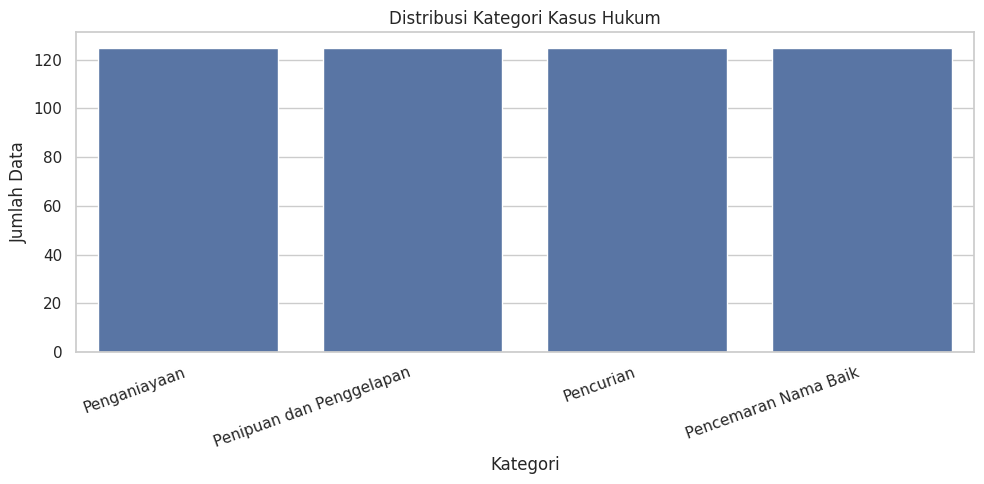

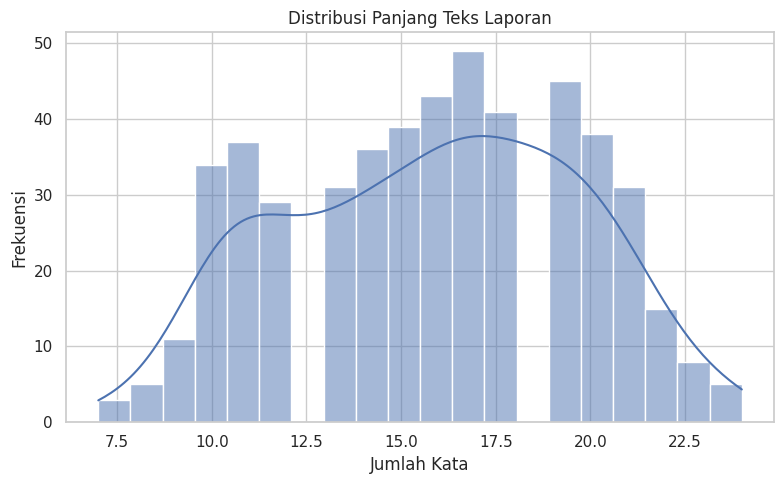


=== EDA DATASET LEGAL QA ===

Distribusi Kategori Legal QA:
kategori
Penipuan dan Penggelapan    172
Pencemaran Nama Baik        156
Penganiayaan                154
Pencurian                   105
Name: count, dtype: int64

Statistik Panjang Pertanyaan:
count    543.000000
mean      72.007366
std       52.646036
min        8.000000
25%       36.000000
50%       58.000000
75%       93.000000
max      433.000000
Name: jumlah_kata_pertanyaan, dtype: float64

Statistik Panjang Jawaban:
count     543.000000
mean     1158.305709
std       435.278808
min       121.000000
25%       820.500000
50%      1145.000000
75%      1454.500000
max      2363.000000
Name: jumlah_kata_jawaban, dtype: float64


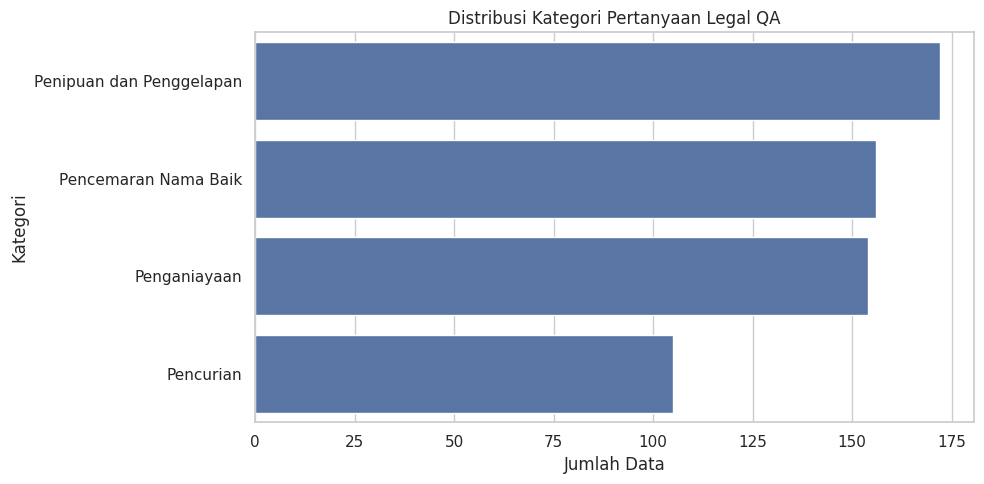

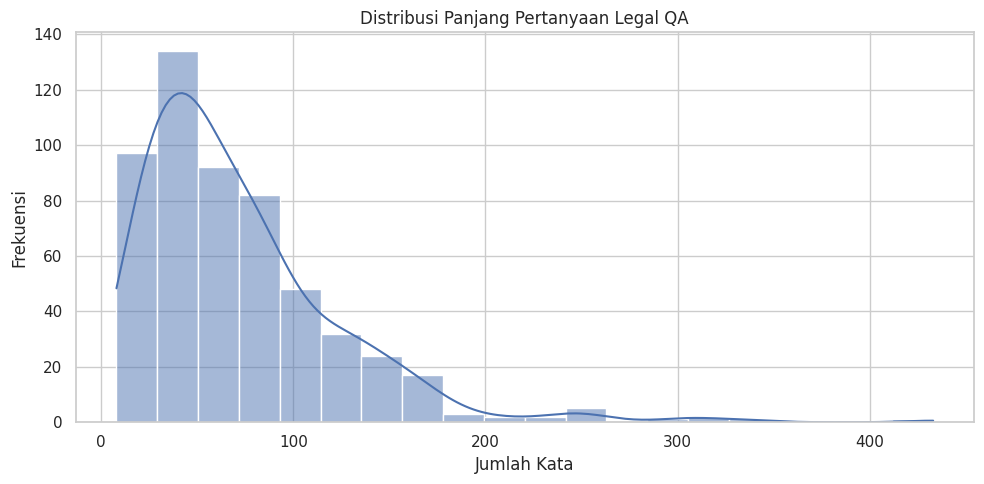

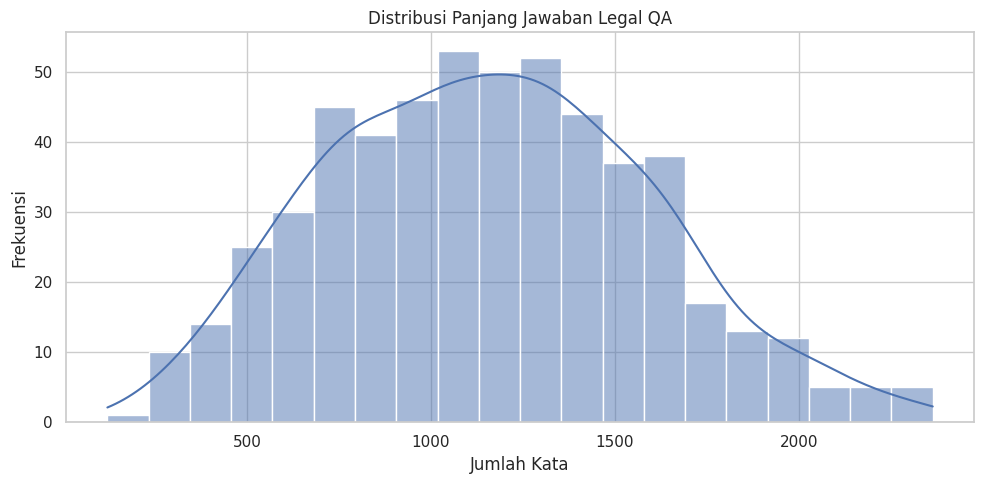

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df_eda_klasifikasi = df_klasifikasi.copy()
df_eda_qa = df_qa.copy()

df_eda_klasifikasi["jumlah_kata"] = df_eda_klasifikasi["teks_laporan"].apply(
    lambda x: len(str(x).split())
)

df_eda_qa["jumlah_kata_pertanyaan"] = df_eda_qa["Question"].apply(
    lambda x: len(str(x).split())
)

df_eda_qa["jumlah_kata_jawaban"] = df_eda_qa["Answer"].apply(
    lambda x: len(str(x).split())
)

print("=== EDA DATASET KLASIFIKASI ===")
print("\nDistribusi Kategori:")
print(df_eda_klasifikasi["kategori"].value_counts())

print("\nStatistik Panjang Teks Laporan:")
print(df_eda_klasifikasi["jumlah_kata"].describe())

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_eda_klasifikasi,
    x="kategori",
    order=df_eda_klasifikasi["kategori"].value_counts().index
)
plt.title("Distribusi Kategori Kasus Hukum")
plt.xlabel("Kategori")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_eda_klasifikasi,
    x="jumlah_kata",
    bins=20,
    kde=True
)
plt.title("Distribusi Panjang Teks Laporan")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()


print("\n=== EDA DATASET LEGAL QA ===")

def pecah_kategori_eda(nilai):
    if isinstance(nilai, (set, list, tuple)):
        return [str(k).strip() for k in nilai if str(k).strip()]

    return [k.strip() for k in str(nilai).split(";") if k.strip()]

kategori_qa = df_eda_qa["kategori"].apply(
    pecah_kategori_eda
).explode()

print("\nDistribusi Kategori Legal QA:")
print(kategori_qa.value_counts())

print("\nStatistik Panjang Pertanyaan:")
print(df_eda_qa["jumlah_kata_pertanyaan"].describe())

print("\nStatistik Panjang Jawaban:")
print(df_eda_qa["jumlah_kata_jawaban"].describe())

plt.figure(figsize=(10, 5))
sns.countplot(
    y=kategori_qa,
    order=kategori_qa.value_counts().index
)
plt.title("Distribusi Kategori Pertanyaan Legal QA")
plt.xlabel("Jumlah Data")
plt.ylabel("Kategori")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_eda_qa,
    x="jumlah_kata_pertanyaan",
    bins=20,
    kde=True
)
plt.title("Distribusi Panjang Pertanyaan Legal QA")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_eda_qa,
    x="jumlah_kata_jawaban",
    bins=20,
    kde=True
)
plt.title("Distribusi Panjang Jawaban Legal QA")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def pecah_kategori(teks):
    return {
        item.strip()
        for item in str(teks).split(";")
        if item.strip()
    }

df_qa = df_qa.reset_index(drop=True).copy()

df_qa["kategori_set"] = df_qa["kategori"].apply(pecah_kategori)

df_qa["teks_pencarian"] = (
    df_qa["Title"].fillna("").astype(str) + " " +
    df_qa["Question"].fillna("").astype(str) + " " +
    df_qa["Answer"].fillna("").astype(str)
)

vectorizer_qa = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    sublinear_tf=True,
    strip_accents=None
)

vektor_qa = vectorizer_qa.fit_transform(df_qa["teks_pencarian"])

print("Mesin pencarian Legal QA berhasil diperbarui.")
print("Jumlah data Legal QA:", len(df_qa))

Mesin pencarian Legal QA berhasil diperbarui.
Jumlah data Legal QA: 543


In [5]:
from sklearn.metrics.pairwise import cosine_similarity

def uji_pencarian_legal_qa(pesan, jumlah=5):
    vektor_pesan = vectorizer_qa.transform([pesan])

    skor = cosine_similarity(
        vektor_pesan,
        vektor_qa
    ).flatten()

    indeks = skor.argsort()[::-1][:jumlah]

    hasil = df_qa.iloc[indeks][
        ["Title", "Question", "kategori", "Link"]
    ].copy()

    hasil["skor_kemiripan"] = skor[indeks]

    return hasil.reset_index(drop=True)

uji_pencarian_legal_qa(
    "Kemarin tetangga saya berkelahi dan salah satu orang masuk rumah sakit."
)

,Title,Question,kategori,Link,skor_kemiripan
0,Batasan Penganiayaan Ringan,Dear Bung Pokrol. Mohon penjelasan lebih jauh ...,Penganiayaan,https://www.hukumonline.com/klinik/a/pasal-352...,0.058017
1,Hukumnya Jika Berkelahi karena Rebutan Pacar,Saya akan menceritakan kronologis di kos yang ...,Penganiayaan,https://www.hukumonline.com/klinik/a/hukumnya-...,0.053964
2,Hukum Duel Satu Lawan Satu,"Assalamualaikum, saya ingin menanyakan apakah ...",Penganiayaan,https://www.hukumonline.com/klinik/a/hukum-due...,0.049707
3,Sanksi Pidana Memasuki Rumah Orang Lain dengan...,Bila ada seseorang yang memasuki rumah kita de...,Penganiayaan,https://www.hukumonline.com/klinik/a/sanksi-pi...,0.048821
4,Bolehkah Korban Menerapkan Denda 10 Kali Harga...,1. Bolehkah memberikan sanksi denda 10 kali li...,Pencurian,https://www.hukumonline.com/klinik/a/memberika...,0.040055


In [6]:
import re
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

BATAS_KEMIRIPAN = 0.02

def deteksi_intent(pesan):
    pesan = pesan.lower().strip()

    kata_sapaan = [
        "hai", "halo", "hello", "hi",
        "selamat pagi", "selamat siang",
        "selamat sore", "selamat malam"
    ]

    kata_konsultasi = [
        "saya mau konsultasi",
        "aku mau konsultasi",
        "ingin konsultasi",
        "mau konsultasi",
        "bisa konsultasi",
        "saya ingin bertanya"
    ]

    kata_advokat = [
        "advokat", "pengacara",
        "bantuan hukum",
        "lembaga bantuan hukum",
        "lbh", "cari pengacara"
    ]

    for kata in kata_sapaan:
        if re.search(r'(?<!\w)' + re.escape(kata) + r'(?!\w)', pesan):
            return "sapaan"

    if any(kata in pesan for kata in kata_konsultasi):
        return "konsultasi"

    if any(kata in pesan for kata in kata_advokat):
        return "rekomendasi_advokat"

    return "laporan"


def chatbot(pesan):
    pesan = str(pesan).strip()

    if not pesan:
        return "Silakan ceritakan masalah hukum yang ingin kamu konsultasikan."

    intent = deteksi_intent(pesan)

    if intent == "sapaan":
        return (
            "Halo! Selamat datang di layanan konsultasi hukum awal.\n\n"
            "Kamu bisa menceritakan masalah hukum atau menanyakan "
            "informasi hukum yang ingin kamu ketahui."
        )

    if intent == "konsultasi":
        return (
            "Tentu, saya siap membantu kamu memulai konsultasi hukum.\n\n"
            "Kamu bisa:\n"
            "1. Menceritakan masalah hukum yang sedang kamu hadapi.\n"
            "2. Meminta informasi mengenai advokat atau LBH.\n\n"
            "Ceritakan kebutuhanmu terlebih dahulu."
        )

    if intent == "rekomendasi_advokat":
        return (
            "Saya bisa membantu mengarahkan pencarian bantuan hukum.\n\n"
            "Saat ini direktori advokat dan LBH belum terhubung "
            "ke sistem, sehingga saya belum bisa memberikan "
            "rekomendasi nama atau kontak yang terverifikasi."
        )

    kategori_prediksi = model_klasifikasi.predict([pesan])[0]

    vektor_pesan = vectorizer_qa.transform([pesan])

    skor_semua = cosine_similarity(
        vektor_pesan,
        vektor_qa
    ).flatten()

    kategori_normal = kategori_prediksi.strip().lower()

    indeks_kategori = [
        i for i, kategori_set in enumerate(df_qa["kategori_set"])
        if any(
            kategori_normal == item.strip().lower()
            for item in kategori_set
        )
    ]

    if not indeks_kategori:
        return (
            f"Kategori sementara: {kategori_prediksi}\n\n"
            "Belum tersedia referensi jawaban untuk kategori ini "
            "dalam dataset Legal QA.\n\n"
            "Silakan ceritakan kronologi kejadian secara lebih lengkap."
        )

    skor_kategori = skor_semua[indeks_kategori]

    posisi_terbaik = int(np.argmax(skor_kategori))
    indeks_terbaik = indeks_kategori[posisi_terbaik]

    skor_terbaik = float(skor_semua[indeks_terbaik])

    if skor_terbaik < BATAS_KEMIRIPAN:
        return (
            f"Kategori sementara: {kategori_prediksi}\n\n"
            "Saya belum menemukan penjelasan hukum yang cukup "
            "relevan dengan cerita kamu.\n\n"
            "Agar saya bisa membantu lebih tepat, ceritakan:\n"
            "1. Bagaimana kronologi kejadian?\n"
            "2. Kapan dan di mana kejadian berlangsung?\n"
            "3. Siapa saja yang terlibat?\n"
            "4. Apakah terdapat saksi atau bukti?"
        )

    data_jawaban = df_qa.iloc[indeks_terbaik]

    hasil = (
        f"Kategori hasil klasifikasi: {kategori_prediksi}\n\n"
        f"Pertanyaan terkait:\n{data_jawaban['Question']}\n\n"
        f"Penjelasan hukum:\n{data_jawaban['Answer']}\n\n"
        f"Sumber: {data_jawaban['Link']}\n"
        f"Skor kemiripan: {skor_terbaik:.3f}\n\n"
        "Catatan: Jawaban ini diambil dari dataset Legal QA "
        "berdasarkan kemiripan teks. Informasi ini merupakan "
        "konsultasi awal dan bukan pengganti nasihat advokat."
    )

    return hasil

In [7]:
print("Variabel yang berkaitan dengan model dan dataset:")

for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "train", "test", "model", "x_", "y_", "data", "label", "kategori"
    ]):
        objek = globals()[nama]
        print(f"{nama}: {type(objek).__name__}")

Variabel yang berkaitan dengan model dan dataset:
data: DataFrame
pecah_kategori: function


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd

X = df_klasifikasi["teks_laporan"].astype(str)
y = df_klasifikasi["kategori"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model_evaluasi = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

model_evaluasi.fit(X_train, y_train)

y_pred = model_evaluasi.predict(X_test)

print("Akurasi:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

contoh_laporan = [
    "Saya ditipu seseorang setelah mentransfer uang untuk membeli barang.",
    "Saya dipukul oleh beberapa orang hingga mengalami luka.",
    "Seseorang mengambil motor saya tanpa izin.",
    "Seseorang menyebarkan fitnah tentang saya di media sosial."
]

print("\n=== PENGUJIAN LAPORAN BARU ===")

for laporan in contoh_laporan:
    prediksi = model_evaluasi.predict([laporan])[0]
    print("Laporan:", laporan)
    print("Prediksi:", prediksi)
    print("-" * 50)

Akurasi: 99.0 %

Classification Report:
                          precision    recall  f1-score   support

    Pencemaran Nama Baik       1.00      1.00      1.00        25
               Pencurian       1.00      0.96      0.98        25
            Penganiayaan       0.96      1.00      0.98        25
Penipuan dan Penggelapan       1.00      1.00      1.00        25

                accuracy                           0.99       100
               macro avg       0.99      0.99      0.99       100
            weighted avg       0.99      0.99      0.99       100


Confusion Matrix:
[[25  0  0  0]
 [ 0 24  1  0]
 [ 0  0 25  0]
 [ 0  0  0 25]]

=== PENGUJIAN LAPORAN BARU ===
Laporan: Saya ditipu seseorang setelah mentransfer uang untuk membeli barang.
Prediksi: Penipuan dan Penggelapan
--------------------------------------------------
Laporan: Saya dipukul oleh beberapa orang hingga mengalami luka.
Prediksi: Penganiayaan
--------------------------------------------------
Laporan: Seseo

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

model_klasifikasi = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

model_klasifikasi.fit(
    df_klasifikasi["teks_laporan"].astype(str),
    df_klasifikasi["kategori"]
)

print("Model klasifikasi berhasil dilatih.")

Model klasifikasi berhasil dilatih.


In [10]:
import joblib
import os
from google.colab import drive

drive.mount('/content/drive')

model_bundle = {
    "model_klasifikasi": model_klasifikasi,
    "vectorizer_qa": vectorizer_qa,
    "vektor_qa": vektor_qa,
    "df_qa": df_qa,
    "batas_kemiripan": BATAS_KEMIRIPAN
}

folder_model = "/content/drive/MyDrive/Capstone"

os.makedirs(folder_model, exist_ok=True)

path_model = os.path.join(
    folder_model,
    "model_konsultasi_hukum.pkl"
)

joblib.dump(model_bundle, path_model, compress=3)

print("Model berhasil disimpan!")
print("Lokasi:", path_model)

Mounted at /content/drive
Model berhasil disimpan!
Lokasi: /content/drive/MyDrive/Capstone/model_konsultasi_hukum.pkl


In [11]:
while True:
    pesan = input("Kamu: ")

    if pesan.lower().strip() in ["keluar", "exit", "quit"]:
        print("Chatbot: Terima kasih telah menggunakan layanan konsultasi hukum.")
        break

    jawaban = chatbot(pesan)

    print("\nChatbot:")
    print(jawaban)
    print()

Kamu: exit
Chatbot: Terima kasih telah menggunakan layanan konsultasi hukum.
